# 01 · Data setup
Download RSNA, label images, split by patient, save `splits.csv` to Drive.

## 0 · Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
PROJECT = Path('/content/drive/MyDrive/345_term_project')
DATA    = PROJECT / 'data'
LOCAL   = Path('/content/rsna')
for p in (DATA, LOCAL):
    p.mkdir(parents=True, exist_ok=True)
print(PROJECT)

Mounted at /content/drive
/content/drive/MyDrive/345_term_project


## 1 · Download data
Skipped if already in Drive (a 403 error means the Kaggle competition hasn't been joined). Then unzip the labeled training images + label CSVs to Colab's local disk.

In [ ]:
import os
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

!pip install -q --upgrade kaggle pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 48.0 MB/s eta 0:00:00


In [ ]:
ZIP = DATA / 'rsna-pneumonia-detection-challenge.zip'
MAPPING = DATA / 'pneumonia-challenge-dataset-mappings_2018.json'

if not ZIP.exists():
    !kaggle competitions download -c rsna-pneumonia-detection-challenge -p "{DATA}"
if not MAPPING.exists():
    !wget -q -O "{MAPPING}" https://s3.amazonaws.com/east1.public.rsna.org/AI/2018/pneumonia-challenge-dataset-mappings_2018.json

!ls -lh "{DATA}"

total 3.7G
-rw------- 1 root root 1.3M Oct 20 19:15 budgets.json
-rw------- 1 root root  17M Jan 29  2019 pneumonia-challenge-dataset-mappings_2018.json
-rw------- 1 root root 3.7G Dec 11  2019 rsna-pneumonia-detection-challenge.zip
-rw------- 1 root root 2.4M Oct 20 19:15 splits.csv
-rw------- 1 root root  101 Oct 20 19:15 split_summary.csv


In [ ]:
if not (LOCAL / 'stage_2_train_images').exists():
    !unzip -q -o "{ZIP}" 'stage_2_train_images/*' stage_2_train_labels.csv stage_2_detailed_class_info.csv -d "{LOCAL}"
print(len(list((LOCAL / 'stage_2_train_images').glob('*.dcm'))), 'DICOMs')

26684 DICOMs


## 2 · Labels
Pneumonia = `Target 1`, everything else = 0. One row per image.

In [ ]:
import pandas as pd, numpy as np

boxes   = pd.read_csv(LOCAL / 'stage_2_train_labels.csv')
classes = pd.read_csv(LOCAL / 'stage_2_detailed_class_info.csv').drop_duplicates('patientId')

df = (boxes.groupby('patientId', as_index=False)
           .agg(label=('Target', 'max'), n_boxes=('x', 'count')))
df = df.merge(classes, on='patientId', how='left').rename(columns={'patientId': 'image_id'})

print(len(df), 'images')
print(df['label'].value_counts(normalize=True).round(3).rename('fraction'))
print(pd.crosstab(df['class'], df['label']))

26684 images
label
0    0.775
1    0.225
Name: fraction, dtype: float64
label                             0     1
class                                    
Lung Opacity                      0  6012
No Lung Opacity / Not Normal  11821     0
Normal                         8851     0


## 3 · Real patient IDs
Kaggle IDs are per image. Map each image to its NIH patient so we can split by person.

In [ ]:
import json
mapping = pd.DataFrame(json.load(open(MAPPING)))[['subset_img_id', 'img_id']]
mapping = mapping.rename(columns={'subset_img_id': 'image_id', 'img_id': 'nih_image'})
mapping['nih_patient'] = mapping['nih_image'].str.split('_').str[0]

df = df.merge(mapping, on='image_id', how='left')
assert df['nih_patient'].notna().all(), f"{df['nih_patient'].isna().sum()} images missing from mapping"

per_patient = df.groupby('nih_patient').size()
print(f'{len(df)} images from {len(per_patient)} real patients')
print(f'{(per_patient > 1).sum()} patients have >1 image; '
      f'{per_patient[per_patient > 1].sum() / len(df):.0%} of images belong to them (max {per_patient.max()} images)')
mixed = df.groupby('nih_patient')['label'].nunique().gt(1).sum()
print(f'{mixed} patients have both pneumonia and non-pneumonia images')

26684 images from 11452 real patients
4355 patients have >1 image; 73% of images belong to them (max 65 images)
1726 patients have both pneumonia and non-pneumonia images


## 4 · Train / val / test split
~70/15/15 by patient, stratified by label, fixed seed.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

SPLIT_SEED = 345

def carve(frame, n_splits, seed):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest, held = next(sgkf.split(frame, frame['label'], groups=frame['nih_patient']))
    return frame.index[rest], frame.index[held]

rest_idx, test_idx = carve(df, n_splits=7, seed=SPLIT_SEED)
train_idx, val_idx = carve(df.loc[rest_idx], n_splits=6, seed=SPLIT_SEED)

df['split'] = 'train'
df.loc[val_idx, 'split'] = 'val'
df.loc[test_idx, 'split'] = 'test'

pats = {s: set(df.loc[df.split == s, 'nih_patient']) for s in ('train', 'val', 'test')}

summary = df.groupby('split').agg(images=('image_id', 'size'), patients=('nih_patient', 'nunique'),
                                  pneumonia_rate=('label', 'mean')).loc[['train', 'val', 'test']]
summary['pneumonia_rate'] = summary['pneumonia_rate'].round(3)
summary

,images,patients,pneumonia_rate
split,,,
train,18881,8168,0.227
val,3966,1650,0.217
test,3837,1634,0.224


## 5 · Save to Drive

In [ ]:
cols = ['image_id', 'label', 'class', 'n_boxes', 'nih_image', 'nih_patient', 'split']
df[cols].to_csv(DATA / 'splits.csv', index=False)
summary.to_csv(DATA / 'split_summary.csv')
!ls -lh "{DATA}"

total 3.7G
-rw------- 1 root root 1.3M Oct 20 19:15 budgets.json
-rw------- 1 root root  17M Jan 29  2019 pneumonia-challenge-dataset-mappings_2018.json
-rw------- 1 root root 3.7G Dec 11  2019 rsna-pneumonia-detection-challenge.zip
-rw------- 1 root root 2.4M Oct 21 13:19 splits.csv
-rw------- 1 root root  101 Oct 21 13:19 split_summary.csv


## 6 · Sample images

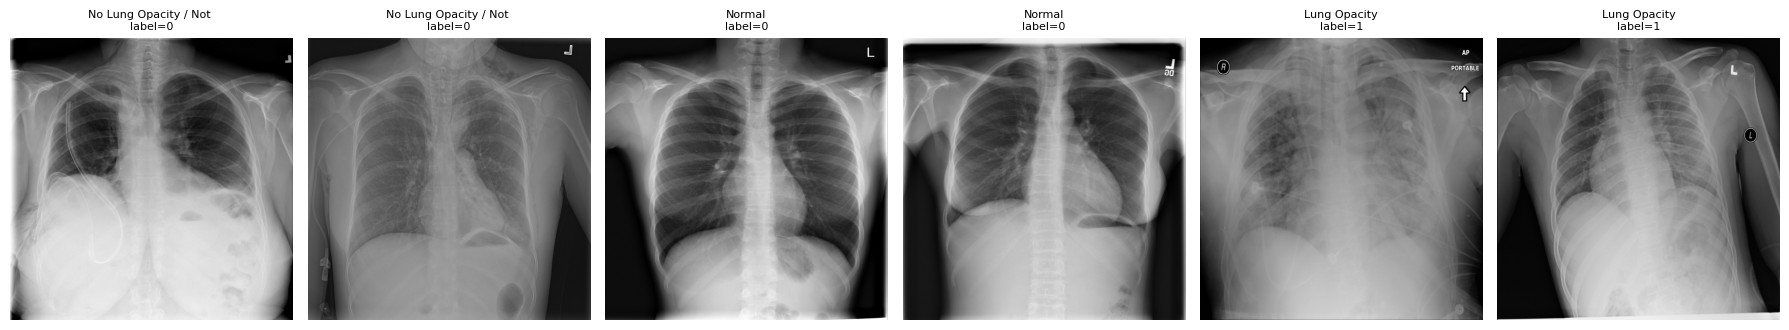

In [ ]:
import pydicom, matplotlib.pyplot as plt

show = pd.concat([df[df['class'] == c].sample(2, random_state=0) for c in df['class'].unique()])
fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3.4))
for ax, (_, r) in zip(axes, show.iterrows()):
    img = pydicom.dcmread(LOCAL / 'stage_2_train_images' / f"{r.image_id}.dcm").pixel_array
    ax.imshow(img, cmap='gray'); ax.axis('off')
    ax.set_title(f"{r['class'][:22]}\nlabel={r.label}", fontsize=8)
plt.tight_layout()